# Chapter 17 — Machine Learning with Scikit-learn

Scikit-learn provides a consistent API for preprocessing, model fitting, evaluation, and model selection. Learn the end-to-end supervised-learning workflow while avoiding leakage and overclaiming.

## Prerequisites
Python, NumPy, Pandas, descriptive statistics, and basic train/test reasoning.

## Learning goals
- Define features, target, task type, and a baseline.
- Split data before fitting transformations.
- Build preprocessing and estimator pipelines.
- Train regression and classification models.
- Evaluate with task-appropriate metrics and cross-validation.
- Recognize leakage, overfitting, and reproducibility requirements.

**Study sequence:** use the theory notebook first, then tutorial, then lab. The examples use the bundled synthetic data unless otherwise noted.

In [1]:
from pathlib import Path
ROOT=Path.cwd()
if not (ROOT/"data").exists() and (ROOT.parent/"data").exists(): ROOT=ROOT.parent
DATA=ROOT/"data"
print("Data directory:", DATA.resolve())

Data directory: /mnt/data/python_data_analysis_book/data


## Guided learning path

Work from top to bottom. Each step states the purpose, explains the API choice, and provides a complete code cell. Modify parameters and predict the output before running it.

### Step 1 — Guided 1 — Define target and baseline

Predict order revenue using observed transaction fields. A mean predictor is a baseline: a more complex model should beat it on held-out data.

In [2]:
from pathlib import Path
ROOT=Path.cwd()
if not (ROOT/"data").exists() and (ROOT.parent/"data").exists(): ROOT=ROOT.parent
DATA=ROOT/"data"
print("Data directory:", DATA.resolve())
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error
sales=pd.read_csv(DATA/"sales.csv"); X=sales[["units","discount"]]; y=sales.revenue
Xtr,Xte,ytr,yte=train_test_split(X,y,test_size=.25,random_state=42)
baseline=DummyRegressor().fit(Xtr,ytr); print("Baseline MAE:",mean_absolute_error(yte,baseline.predict(Xte)))

Data directory: /mnt/data/python_data_analysis_book/data
Baseline MAE: 179953.2602666667


### Step 2 — Guided 2 — Fit and evaluate a linear model

The test set is held aside until model selection is complete. These sample data are synthetic and the exercise is for workflow learning, not production decision-making.

In [3]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
reg=LinearRegression().fit(Xtr,ytr); pred=reg.predict(Xte)
print({"MAE":mean_absolute_error(yte,pred),"RMSE":mean_squared_error(yte,pred)**.5,"R2":r2_score(yte,pred)})

{'MAE': 181515.6312489557, 'RMSE': 245712.82270191083, 'R2': 0.1121177879642582}


### Step 3 — Guided 3 — Compare with cross-validation

Cross-validation estimates variation over training folds. For time-dependent data, use a time-aware split rather than shuffled folds.

In [4]:
from sklearn.model_selection import cross_val_score
scores=cross_val_score(LinearRegression(),Xtr,ytr,cv=5,scoring="neg_mean_absolute_error"); print("Fold MAE:",-scores,"Average:",-scores.mean())

Fold MAE: [260422.15903939 228261.71418321 136962.33291029 201759.47766682
 213187.74468593] Average: 208118.6856971278


### Step 4 — Guided 4 — Inspect residuals

A residual plot can reveal systematic errors and variance changes. Performance should also be compared across important subgroups.

/mnt/data/python_data_analysis_book/Chapter_17_machine_learning_with_scikit_learn/Chapter_17_Step_by_Step_Tutorial.ipynb:2: UserWarning:

FigureCanvasAgg is non-interactive, and thus cannot be shown



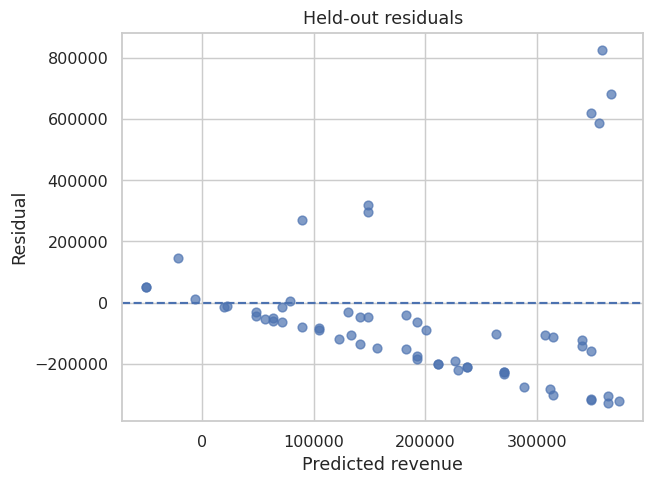

In [5]:
import matplotlib.pyplot as plt
plt.scatter(pred,yte-pred,alpha=.7); plt.axhline(0,ls="--"); plt.xlabel("Predicted revenue"); plt.ylabel("Residual"); plt.title("Held-out residuals"); plt.show()

## Tutorial checkpoint

1. What was the input data type?
2. What did the function or method return?
3. Which argument most changed the result?
4. What edge case should be tested before using this in production?